In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting aesthetics
plt.style.use('seaborn-v0\_8-whitegrid' if 'seaborn-v0\_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['font.size'] = 11

<>:7: SyntaxWarning: invalid escape sequence '\_'
<>:7: SyntaxWarning: invalid escape sequence '\_'
<>:7: SyntaxWarning: invalid escape sequence '\_'
<>:7: SyntaxWarning: invalid escape sequence '\_'
C:\Users\HP\AppData\Local\Temp\ipykernel_18756\988771377.py:7: SyntaxWarning: invalid escape sequence '\_'
  plt.style.use('seaborn-v0\_8-whitegrid' if 'seaborn-v0\_8-whitegrid' in plt.style.available else 'default')
C:\Users\HP\AppData\Local\Temp\ipykernel_18756\988771377.py:7: SyntaxWarning: invalid escape sequence '\_'
  plt.style.use('seaborn-v0\_8-whitegrid' if 'seaborn-v0\_8-whitegrid' in plt.style.available else 'default')


In [2]:
data = pd.read_csv('used_cars.csv')

In [3]:
print("Dataset shape: ",data.shape)
data.info()

Dataset shape:  (188533, 13)
<class 'pandas.DataFrame'>
RangeIndex: 188533 entries, 0 to 188532
Data columns (total 13 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   id            188533 non-null  int64
 1   brand         188533 non-null  str  
 2   model         188533 non-null  str  
 3   model_year    188533 non-null  int64
 4   milage        188533 non-null  int64
 5   fuel_type     183450 non-null  str  
 6   engine        188533 non-null  str  
 7   transmission  188533 non-null  str  
 8   ext_col       188533 non-null  str  
 9   int_col       188533 non-null  str  
 10  accident      186081 non-null  str  
 11  clean_title   167114 non-null  str  
 12  price         188533 non-null  int64
dtypes: int64(4), str(9)
memory usage: 18.7 MB


In [4]:
data.sample(5)

,id,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
13922,13922,BMW,M2 Competition,2023,2800,Gasoline,503.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,8-Speed A/T,Green,Brown,None reported,Yes,149500
90523,90523,Nissan,Armada Platinum,2018,50000,Gasoline,390.0HP 5.6L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Blue,Gray,None reported,Yes,20000
16122,16122,Rivian,R1S Launch Edition,2022,6785,NaN,835.0HP Electric Motor Electric Fuel System,8-Speed A/T,Green,Gray,None reported,Yes,92500
63789,63789,Dodge,Challenger SRT Demon,2023,9000,Gasoline,808.0HP 6.2L 8 Cylinder Engine Gasoline Fuel,8-Speed A/T,Black,Black,None reported,Yes,98900
114152,114152,Chevrolet,Bolt EUV Premier,2022,19200,Hybrid,369.0HP 1.5L 3 Cylinder Engine Plug-In Electri...,A/T,Black,Black,None reported,Yes,48950


In [5]:
data.isnull().sum()

id                  0
brand               0
model               0
model_year          0
milage              0
fuel_type        5083
engine              0
transmission        0
ext_col             0
int_col             0
accident         2452
clean_title     21419
price               0
dtype: int64

In [6]:
# Summary statistics for numerical variables
num_cols = data.select_dtypes(include=[np.number]).columns.tolist()

desc_stats = data[num_cols].describe().T
desc_stats['skew'] = data[num_cols].skew()
desc_stats[['count','mean','std','min','50%','max','min','skew']].round(2)
desc_stats

,count,mean,std,min,25%,50%,75%,max,skew
id,188533.0,94266.000000,54424.933488,0.0,47133.0,94266.0,141399.0,188532.0,1.816205e-17
model_year,188533.0,2015.829998,5.660967,1974.0,2013.0,2017.0,2020.0,2024.0,-1.044511e+00
milage,188533.0,65705.295174,49798.158076,100.0,24115.0,57785.0,95400.0,405000.0,8.950620e-01
price,188533.0,43878.016178,78819.522254,2000.0,17000.0,30825.0,49900.0,2954083.0,2.026845e+01


             missing_count  missing_percentage
clean_title          21419               11.36
fuel_type             5083                2.70
accident              2452                1.30


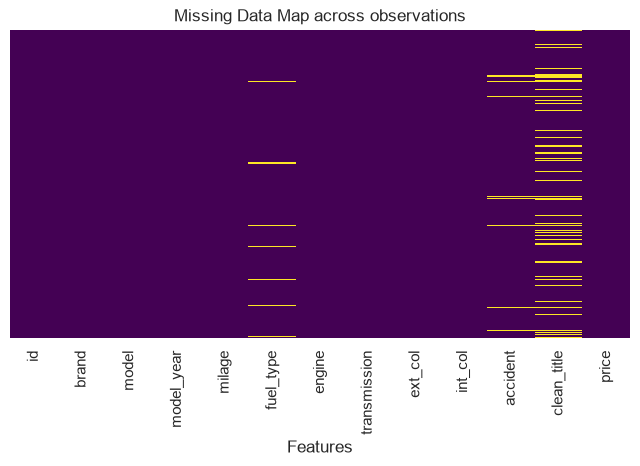

In [7]:
# Missing Value Diagnostic (MCAR / MAR)

missing_summary = pd.DataFrame({
    'missing_count': data.isnull().sum(),
    'missing_percentage': (data.isnull().sum()/len(data))*100
}).query('missing_count > 0').sort_values('missing_percentage', ascending=False)

print(missing_summary.round(2))

# Visualize missingness pattern
if not missing_summary.empty:
    plt.figure(figsize=(8,4))
    sns.heatmap(data.isnull(), cbar=False, cmap='viridis', yticklabels=False)
    plt.title("Missing Data Map across observations")
    plt.xlabel("Features")
    plt.show()

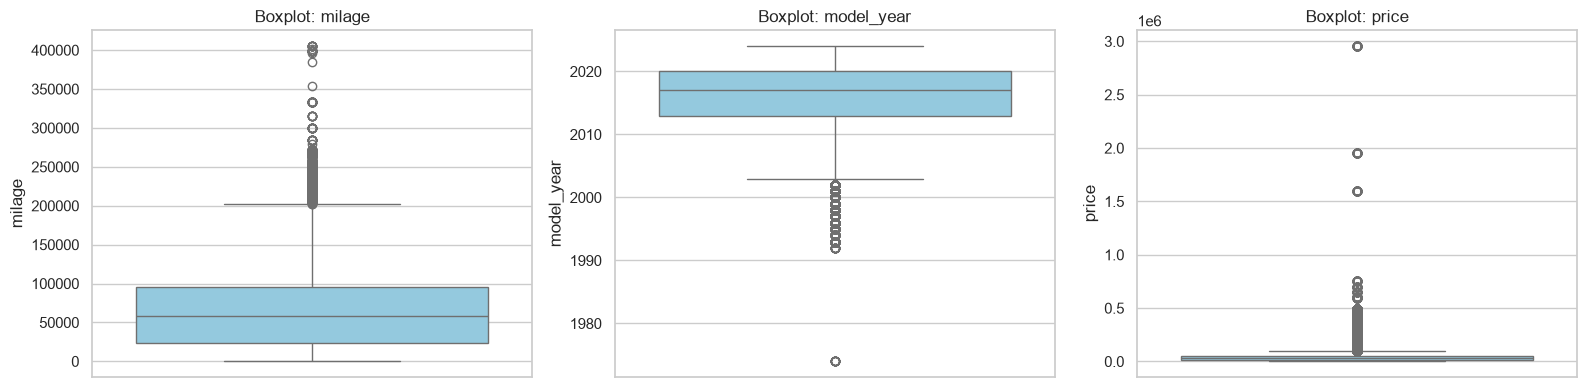

In [8]:
# Visualise with Boxplots

fig, axes = plt.subplots(1,3,figsize=(16,4))
for i, col in enumerate(['milage', 'model_year', 'price']):
    sns.boxplot(y=data[col], ax=axes[i], color='skyblue')
    axes[i].set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()

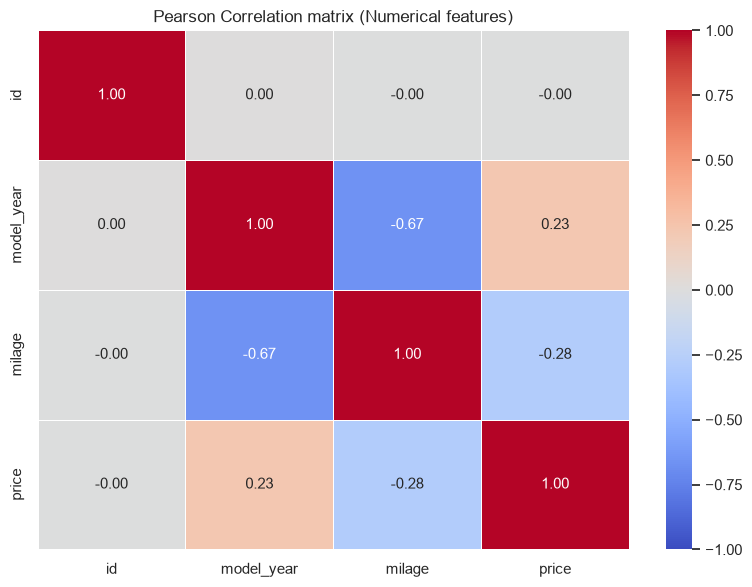

In [9]:
# Collinearity and Correlation matrix

plt.figure(figsize=(8,6))
corr_matrix = data[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidth=0.5)
plt.title("Pearson Correlation matrix (Numerical features)")
plt.tight_layout()
plt.show()

In [10]:
# Categorical Variables Inspection

cat_cols = data.select_dtypes(include=['object','category']).columns.tolist()
for col in cat_cols:
    print(f"\n---Value counts: {col} ---")
    val_counts = data[col].value_counts(dropna=False)
    val_pct = data[col].value_counts(normalize=True, dropna=False) * 100
    cat_df = pd.DataFrame({'Count': val_counts, 'Percentage': val_pct.round(1)})
    print(cat_df)

# Relationship between categorical features and target price
# fig, axes = plt.subplots(1,len(cat_cols), figsize=(15,4))
# for i, col in enumerate(cat_cols):
#     sns.boxplot(x=col, y='price', data=data, ax=axes[i], palette='Set2')
#     axes[i].set_title(f"Price vs {col}")
#     axes[i].tick_params(axis='x', rotation=30)
# plt.tight_layout()
# plt.show()


---Value counts: brand ---
               Count  Percentage
brand                           
Ford           23088        12.2
Mercedes-Benz  19172        10.2
BMW            17028         9.0
Chevrolet      16335         8.7
Audi           10887         5.8
Porsche        10612         5.6
Land            9525         5.1
Toyota          8850         4.7
Lexus           8643         4.6
Jeep            6474         3.4
Cadillac        4674         2.5
RAM             4249         2.3
Nissan          3930         2.1
Tesla           3738         2.0
INFINITI        3276         1.7
GMC             3215         1.7
Dodge           3133         1.7
Mazda           2719         1.4
Kia             2497         1.3
Lincoln         2423         1.3
Subaru          2381         1.3
Acura           2282         1.2
Honda           2101         1.1
Hyundai         2045         1.1
Volkswagen      1765         0.9
Jaguar          1319         0.7
Bentley         1155         0.6
MINI           

C:\Users\HP\AppData\Local\Temp\ipykernel_18756\2395215203.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data.select_dtypes(include=['object','category']).columns.tolist()


In [11]:
# for col in cat_cols:
#     plt.figure(figsize=(12,6))

#     top_categories = data[col].value_counts().nlargest(15).index
#     plot_data = data[data[col].isin(top_categories)]

#     sns.boxplot(y=col, x='price', data=plot_data, palette='Set2')

#     plt.title(f"Price vs {col} (Top 15 categories)")
#     plt.xlabel("Price")
#     plt.ylabel(col)
#     plt.tight_layout()
#     plt.show()

In [12]:
# Cleaning data

#1 dropping useless cols
#data_cleaned = data.drop(columns=['id', 'clean_title'])

#2 frequency binning
def freq_binning(data, col, top_n=10):
    top_categories = data[col].value_counts().nlargest(top_n).index
    return data[col].apply(lambda x : x if x in top_categories else 'Other')

data_cleaned['ext_col_binned'] = freq_binning(data_cleaned, 'ext_col', top_n=10)
data_cleaned['int_col_binned'] = freq_binning(data_cleaned, 'int_col', top_n=10)
data_cleaned = data_cleaned.drop(columns=['ext_col','int_col'])

#3 target encoding (replace model/engine strings with their avg price)
model_target_mean = data_cleaned.groupby('model')['price'].mean()
engine_target_mean = data_cleaned.groupby('engine')['price'].mean()

data_cleaned['model_encoded'] = data_cleaned['model'].map(model_target_mean)
data_cleaned['engine_encoded'] = data_cleaned['engine'].map(engine_target_mean)
data_cleaned = data_cleaned.drop(columns=['model','engine'])

print(data_cleaned[['model_encoded','engine_encoded','ext_col_binned','price']].head())

NameError: name 'data_cleaned' is not defined

In [ ]:
# Save the cleaned dataset to a new CSV file
#data_cleaned.to_csv("cleaned_used_cars.csv", index=False)